# TSO-DTF - Base paper figures + extra graphs (Google Colab)

Re-draws **every figure of the base paper** (Wellens, Boute & Udenio, 2023) for this project, and turns its result **tables into graphs**,
then adds **new graphs** that the base paper does not have.

| Base paper | This notebook |
|---|---|
| Fig. 1 Framework summary | Fig. 1 TSO-DTF framework |
| Fig. 2 ADI / CV² classification | Fig. 2 Demand classification of the 9,119 series |
| Fig. 3 Accuracy vs benchmarks | Fig. 3 RMSSE + SME vs Naive, sNaive, MA, ES, CRO, ADIDA, base paper DTF |
| Fig. 4 SHAP pie charts | Fig. 4 SHAP by data source and raw vs engineered inputs |
| Fig. 5 SHAP dependence plots | Fig. 5 SHAP dependence plots |
| Table 4 M5 validation | Fig. 6 Accuracy at every M5 level |
| Table 5 Inventory | Fig. 7 Inventory performance |
| Table C.8 Per demand category | Fig. 8 Accuracy per demand pattern |
| (new) | Fig. 9 Ablation, Fig. 10 Bootstrap interval, Fig. 11 Per-product improvement, Fig. 12 Service vs stock trade-off |

**Needs in Drive:** `m5_data` (calendar, sell_prices, sales_train_evaluation) and in `m5_results`: `baseline_predictions.csv.gz`,
`optimization4/5/6/7/10_predictions.csv.gz`, `eval_products.csv`. **Run:** Runtime -> Run all (about 15-20 minutes).
All figures are saved in `m5_results/base_paper_figures`.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/m5_data"
RES_DIR = "/content/drive/MyDrive/m5_results"


Mounted at /content/drive


## Step 1 - Load data and forecasts

In [2]:
import os, glob, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon, norm
plt.rcParams.update({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e8e8e8", "axes.axisbelow": True, "figure.dpi": 110})
BASE, OURS, NEG = "#9a9a95", "#2a78d6", "#d03b3b"
FIG_DIR = f"{RES_DIR}/base_paper_figures"; os.makedirs(FIG_DIR, exist_ok=True)
def find(name):
    hits = glob.glob(f"{RES_DIR}/**/{name}", recursive=True)
    if not hits: raise FileNotFoundError(f"{name} not found in {RES_DIR}")
    return hits[0]

pp = pd.read_csv(find("eval_products.csv"))                     # the 9,119 scored series (same for every method)
cal = pd.read_csv(f"{DATA_DIR}/calendar.csv", parse_dates=["date"])
sales = pd.concat([ch[ch["store_id"].isin(["CA_1", "TX_1", "WI_1"])] for ch in pd.read_csv(f"{DATA_DIR}/sales_train_evaluation.csv", chunksize=3000)])
sales = pp[["store_id", "item_id"]].merge(sales, on=["store_id", "item_id"], how="left")
dcols = [c for c in sales.columns if c.startswith("d_")]
Y = sales[dcols].values.astype(float); N = len(pp)
T0 = int(np.where(cal["date"].values[:len(dcols)] == np.datetime64("2016-03-22"))[0][0]); T = 62
A = Y[:, T0:T0 + T]                                             # actual sales in the test period
print(f"{N:,} series | test {cal.date.iloc[T0].date()} to {cal.date.iloc[T0 + T - 1].date()} ({T} days)")

def load_pred(fname):
    p = pd.read_csv(find(fname), parse_dates=["date"])
    p = pp[["store_id", "item_id"]].reset_index().merge(p, on=["store_id", "item_id"]).sort_values(["index", "date"])
    assert len(p) == N * T, f"{fname}: {len(p)} rows, expected {N * T}"
    assert np.allclose(p["sales"].values.reshape(N, T), A), f"{fname}: actuals do not match"
    return np.maximum(p["pred"].values.reshape(N, T), 0)
F = {"Baseline DTF": load_pred("baseline_predictions.csv.gz"),
     "Opt 4": load_pred("optimization4_predictions.csv.gz"), "Opt 5": load_pred("optimization5_predictions.csv.gz"),
     "Opt 6": load_pred("optimization6_predictions.csv.gz"), "Opt 7": load_pred("optimization7_predictions.csv.gz"),
     "Opt 10": load_pred("optimization10_predictions.csv.gz")}
F["Ensemble 4+5"] = (F["Opt 4"] + F["Opt 5"]) / 2
F["TSO-DTF (final)"] = (F["Opt 4"] + F["Opt 5"] + F["Opt 6"] + F["Opt 7"] + F["Opt 10"]) / 5   # equal-weight ensemble
print("Loaded:", list(F))
warnings.filterwarnings("ignore", category=RuntimeWarning); pd.set_option("display.width", 200)
def save(fig, name): fig.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight"); plt.show()


9,119 series | test 2016-03-22 to 2016-05-22 (62 days)
Loaded: ['Baseline DTF', 'Opt 4', 'Opt 5', 'Opt 6', 'Opt 7', 'Opt 10', 'Ensemble 4+5', 'TSO-DTF (final)']


## Step 2 - Metrics (base paper RMSSE Eq. 1, SME Eq. 2, official M5 WRMSSE)

In [3]:
first = np.argmax(Y[:, :T0] > 0, axis=1)
scale = np.array([np.mean(np.diff(Y[i, first[i]:T0]) ** 2) for i in range(N)])          # RMSSE scale (from first sale)
mad = np.mean(np.abs(np.diff(Y[:, T0 - 365:T0], axis=1)), axis=1)                         # SME scale (365-day history)
w = pp["weight"].values
def product_metrics(P):
    e = A - P; r = np.sqrt(np.mean(e ** 2, axis=1) / scale)
    return {"WRMSSE (product level)": (w * r).sum() / w.sum(), "RMSSE mean (Eq. 1)": r.mean(), "RMSSE median": np.median(r),
            "RMSE": np.sqrt((e ** 2).mean()), "MAE": np.abs(e).mean(), "WAPE": np.abs(e).sum() / A.sum(),
            "SME bias (Eq. 2)": np.nanmean(np.mean(e, axis=1) / mad)}, r

# ---- official M5 multi-level WRMSSE ----
prices = pd.concat([ch[ch["store_id"].isin(["CA_1", "TX_1", "WI_1"])] for ch in pd.read_csv(f"{DATA_DIR}/sell_prices.csv", chunksize=500000)])
pm = prices.pivot_table(index=["store_id", "item_id"], columns="wm_yr_wk", values="sell_price").reindex(pd.MultiIndex.from_frame(pp[["store_id", "item_id"]]))
wk = cal["wm_yr_wk"].values[:len(dcols)]
P28 = pm.reindex(columns=wk[T0 - 28:T0]).values
rev28 = np.nansum(Y[:, T0 - 28:T0] * np.nan_to_num(P28), axis=1)                           # weights: revenue 28 days before test
dept = np.array([i.rsplit("_", 1)[0] for i in pp.item_id]); catg = np.array([i.split("_")[0] for i in pp.item_id]); st = pp.store_id.values
LEVELS = {"Total": np.zeros(N, int), "Store": st, "Category": catg, "Department": dept, "Store-category": np.char.add(st, catg),
          "Store-department": np.char.add(st, dept), "Product (all stores)": pp.item_id.values, "Product-store": np.arange(N)}
OFFICIAL_12 = ["Total", "Store", "Store", "Category", "Department", "Store-category", "Store-category",
               "Store-department", "Store-department", "Product (all stores)", "Product-store", "Product-store"]  # 1 store per state
PRE = {}
for lv, g in LEVELS.items():
    codes = pd.Series(g).astype("category").cat.codes.values; K = codes.max() + 1
    agg = lambda M, codes=codes, K=K: np.vstack([np.bincount(codes, weights=M[:, t], minlength=K) for t in range(M.shape[1])]).T
    Yh = agg(Y[:, :T0]); sc = np.array([np.mean(np.diff(y[np.argmax(y > 0):]) ** 2) for y in Yh])
    wl = np.bincount(codes, weights=rev28, minlength=K); ok = sc > 0
    PRE[lv] = (codes, K, agg, agg(A)[ok], sc[ok], wl[ok] / wl[ok].sum(), ok)
def level_wrmsse(P, lv, days=slice(None)):
    codes, K, agg, Aa, sc, wl, ok = PRE[lv]; Pa = agg(P)[ok]
    return (wl * np.sqrt(np.mean((Aa[:, days] - Pa[:, days]) ** 2, axis=1) / sc)).sum()
def official(P, days=slice(None)):
    return np.mean([level_wrmsse(P, lv, days) for lv in OFFICIAL_12])
B, E = F["Baseline DTF"], F["TSO-DTF (final)"]
print(f"Official M5 score: base paper DTF {official(B):.4f} -> TSO-DTF {official(E):.4f}")


Official M5 score: base paper DTF 0.5563 -> TSO-DTF 0.5392


## Step 3 - Base paper benchmarks on the same series and days (next-day forecasts)
Naive, seasonal naive, moving average, exponential smoothing (ES), Croston (CRO) and ADIDA - the benchmarks of the base paper.

In [4]:
def bm_naive(): return Y[:, T0 - 1:T0 + T - 1]
def bm_snaive(): return Y[:, T0 - 7:T0 + T - 7]
cs = np.concatenate([np.zeros((N, 1)), np.cumsum(Y, axis=1)], axis=1)
def bm_ma():                                                    # window 2-14 chosen per series on the last year
    best_k, best = np.full(N, 7), np.full(N, np.inf); t = np.arange(T0 - 365, T0)
    for k in range(2, 15):
        mse = np.mean((Y[:, t] - (cs[:, t] - cs[:, t - k]) / k) ** 2, axis=1); m = mse < best; best[m] = mse[m]; best_k[m] = k
    t = np.arange(T0, T0 + T); Fm = np.zeros((N, T))
    for k in range(2, 15): m = best_k == k; Fm[m] = ((cs[:, t] - cs[:, t - k]) / k)[m]
    return Fm
def bm_ses():                                                   # smoothing constant chosen per series on the last year
    best, Fb = np.full(N, np.inf), np.zeros((N, T))
    for a in np.round(np.arange(0.05, 1.0, 0.05), 2):
        lvl_ = Y[:, T0 - 393:T0 - 365].mean(axis=1); sse = np.zeros(N); Fa = np.zeros((N, T))
        for t in range(T0 - 365, T0 + T):
            if t >= T0: Fa[:, t - T0] = lvl_
            else: sse += (Y[:, t] - lvl_) ** 2
            lvl_ = lvl_ + a * (Y[:, t] - lvl_)
        m = sse < best; best[m] = sse[m]; Fb[m] = Fa[m]
    return Fb
def bm_croston(a=0.1):
    z, p, q, Fc = np.full(N, np.nan), np.full(N, np.nan), np.ones(N), np.zeros((N, T))
    for t in range(T0 + T):
        if t >= T0: Fc[:, t - T0] = np.where(np.isnan(z), 0, z / p)
        y = Y[:, t]; pos = y > 0; first = pos & np.isnan(z); upd = pos & ~first
        z[first] = y[first]; p[first] = q[first]
        z[upd] += a * (y[upd] - z[upd]); p[upd] += a * (q[upd] - p[upd]); q = np.where(pos, 1, q + 1)
    return Fc
def bm_adida(a=0.1, b=7):                                       # weekly aggregation + SES, spread evenly over the days
    st_, Fd = np.full((b, N), np.nan), np.zeros((N, T))
    for t in range(b, T0 + T):
        if t >= T0: Fd[:, t - T0] = np.nan_to_num(st_[(t - 1) % b]) / b
        s_ = cs[:, t + 1] - cs[:, t + 1 - b]; ph = t % b; st_[ph] = np.where(np.isnan(st_[ph]), s_, st_[ph] + a * (s_ - st_[ph]))
    return Fd
BM = {"Naive": bm_naive(), "sNaive": bm_snaive(), "MA": bm_ma(), "ES": bm_ses(), "CRO": bm_croston(), "ADIDA": bm_adida()}
ALL = {**BM, "Base paper DTF": B, "TSO-DTF": E}
mad = np.mean(np.abs(np.diff(Y[:, T0 - 365:T0], axis=1)), axis=1)   # SME scale
def rmsse_sme(P): e = A - P; return np.sqrt(np.mean(e ** 2, axis=1) / scale), np.mean(e, axis=1) / mad
RS = {k: rmsse_sme(v) for k, v in ALL.items()}
summary = pd.DataFrame({k: {"RMSSE (mean)": r.mean(), "WRMSSE": (w * r).sum() / w.sum(), "SME": np.nanmean(s)} for k, (r, s) in RS.items()}).T
print(summary.round(4))


                RMSSE (mean)  WRMSSE     SME
Naive                 1.0054  1.1043  0.0088
sNaive                1.0065  1.1079  0.0222
MA                    0.7575  0.8587  0.0189
ES                    0.7445  0.8486  0.0358
CRO                   0.7643  0.8846  0.0993
ADIDA                 0.7527  0.8777  0.1795
Base paper DTF        0.7302  0.8069  0.0067
TSO-DTF               0.7260  0.7998 -0.0013


# Part A - Base paper figures, redone for TSO-DTF
### Fig. 1 - Framework summary

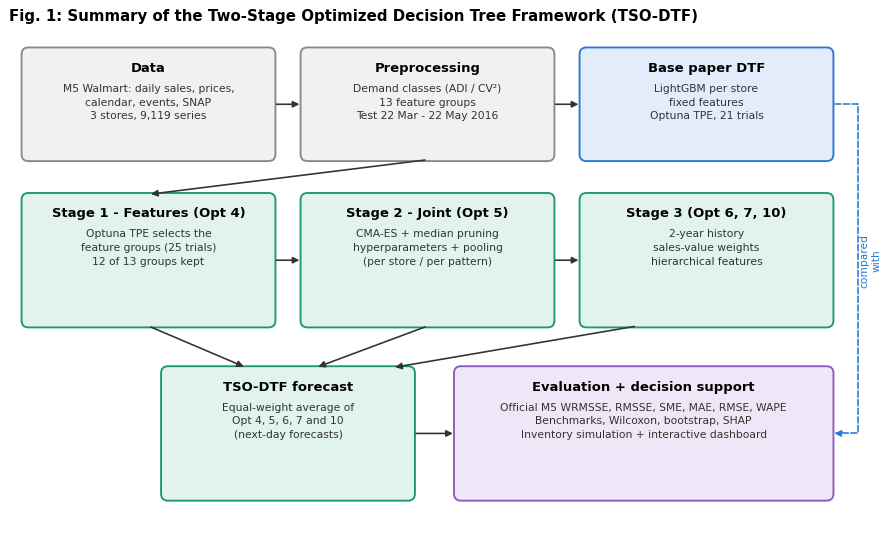

In [5]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12.6, 7.2)); ax.set_xlim(0, 12.6); ax.set_ylim(0, 7.2); ax.axis("off")
def box(x, y, w_, h, title, body, fc, ec):
    ax.add_patch(FancyBboxPatch((x, y), w_, h, boxstyle="round,pad=0.02,rounding_size=0.1", fc=fc, ec=ec, lw=1.5))
    ax.text(x + w_ / 2, y + h - 0.18, title, ha="center", va="top", fontsize=10.5, fontweight="bold")
    ax.text(x + w_ / 2, y + h - 0.5, body, ha="center", va="top", fontsize=8.6, linespacing=1.45, color="#333")
def arrow(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.3))
G_, B_, O_, P_ = ("#f1f1ef", "#8a8a85"), ("#e3ecfa", "#2a78d6"), ("#e1f3ea", "#1a9a68"), ("#efe7f7", "#8a5cc2")
box(0.2, 5.3, 3.6, 1.6, "Data", "M5 Walmart: daily sales, prices,\ncalendar, events, SNAP\n3 stores, 9,119 series", *G_)
box(4.2, 5.3, 3.6, 1.6, "Preprocessing", "Demand classes (ADI / CV²)\n13 feature groups\nTest 22 Mar - 22 May 2016", *G_)
box(8.2, 5.3, 3.6, 1.6, "Base paper DTF", "LightGBM per store\nfixed features\nOptuna TPE, 21 trials", *B_)
box(0.2, 2.9, 3.6, 1.9, "Stage 1 - Features (Opt 4)", "Optuna TPE selects the\nfeature groups (25 trials)\n12 of 13 groups kept", *O_)
box(4.2, 2.9, 3.6, 1.9, "Stage 2 - Joint (Opt 5)", "CMA-ES + median pruning\nhyperparameters + pooling\n(per store / per pattern)", *O_)
box(8.2, 2.9, 3.6, 1.9, "Stage 3 (Opt 6, 7, 10)", "2-year history\nsales-value weights\nhierarchical features", *O_)
box(2.2, 0.4, 3.6, 1.9, "TSO-DTF forecast", "Equal-weight average of\nOpt 4, 5, 6, 7 and 10\n(next-day forecasts)", *O_)
box(6.4, 0.4, 5.4, 1.9, "Evaluation + decision support", "Official M5 WRMSSE, RMSSE, SME, MAE, RMSE, WAPE\nBenchmarks, Wilcoxon, bootstrap, SHAP\nInventory simulation + interactive dashboard", *P_)
arrow(3.8, 6.1, 4.2, 6.1); arrow(7.8, 6.1, 8.2, 6.1); arrow(6.0, 5.3, 2.0, 4.8); arrow(3.8, 3.85, 4.2, 3.85); arrow(7.8, 3.85, 8.2, 3.85)
arrow(9.0, 2.9, 5.5, 2.3); arrow(6.0, 2.9, 4.4, 2.3); arrow(2.0, 2.9, 3.4, 2.3); arrow(5.8, 1.35, 6.4, 1.35)
ax.annotate("", xy=(11.8, 1.35), xytext=(11.8, 6.1), arrowprops=dict(arrowstyle="-|>", color="#2a78d6", lw=1.3, ls="--", connectionstyle="bar,fraction=-0.08"))
ax.text(12.35, 3.85, "compared\nwith", ha="center", va="center", fontsize=8.5, color="#2a78d6", rotation=90)
ax.set_title("Fig. 1: Summary of the Two-Stage Optimized Decision Tree Framework (TSO-DTF)", loc="left", fontweight="bold", fontsize=12)
save(fig, "fig01_framework")


### Fig. 2 - Demand classification (ADI vs CV²)

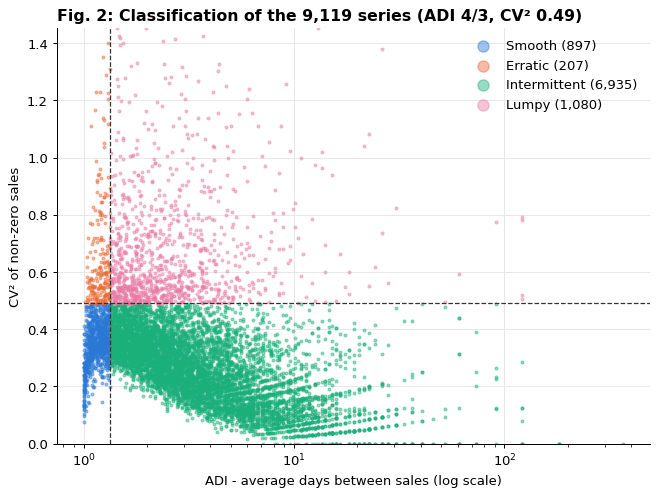

In [6]:
H = Y[:, T0 - 365:T0]; nzc = (H > 0).sum(axis=1)
ADI = H.shape[1] / np.maximum(nzc, 1)
CV2 = np.array([(h[h > 0].std() / h[h > 0].mean()) ** 2 if (h > 0).sum() > 1 else 0 for h in H])
CLS = pp["category"].values; COL = {"smooth": "#2a78d6", "erratic": "#eb6834", "intermittent": "#1baf7a", "lumpy": "#e87ba4"}
fig, ax = plt.subplots(figsize=(8.5, 6))
for c in COL: m = CLS == c; ax.scatter(ADI[m], CV2[m], s=5, alpha=.45, color=COL[c], label=f"{c.capitalize()} ({m.sum():,})")
ax.axvline(4 / 3, color="#333", ls="--", lw=1); ax.axhline(0.49, color="#333", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("ADI - average days between sales (log scale)"); ax.set_ylabel("CV² of non-zero sales")
ax.set_ylim(0, min(4, np.percentile(CV2, 99.5))); ax.legend(frameon=False, markerscale=4, loc="upper right")
ax.set_title(f"Fig. 2: Classification of the {N:,} series (ADI 4/3, CV² 0.49)", loc="left", fontweight="bold")
save(fig, "fig02_demand_classification")


### Fig. 3 - Forecast accuracy and bias of TSO-DTF, base paper DTF and the benchmarks

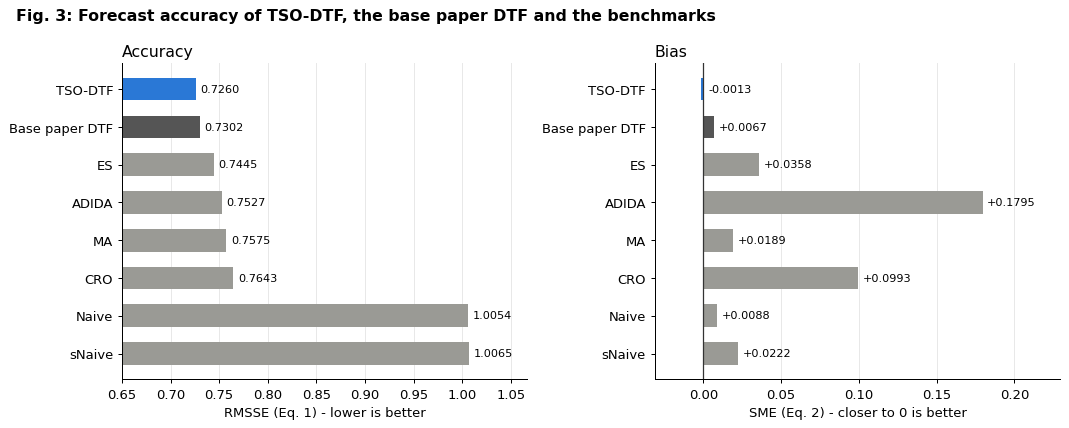

In [7]:
order_ = summary.sort_values("RMSSE (mean)", ascending=False).index
cols_ = [OURS if k == "TSO-DTF" else ("#555" if k == "Base paper DTF" else BASE) for k in order_]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
v = summary.loc[order_, "RMSSE (mean)"]; axs[0].barh(order_, v, color=cols_, height=.6)
for i, x_ in enumerate(v): axs[0].text(x_ + .005, i, f"{x_:.4f}", va="center", fontsize=9)
axs[0].set_xlim(0.65, v.max() * 1.06); axs[0].set_xlabel("RMSSE (Eq. 1) - lower is better"); axs[0].set_title("Accuracy", loc="left")
v = summary.loc[order_, "SME"]; axs[1].barh(order_, v, color=cols_, height=.6); axs[1].axvline(0, color="#333", lw=1)
for i, x_ in enumerate(v): axs[1].text(max(x_, 0) + .003, i, f"{x_:+.4f}", va="center", ha="left", fontsize=9)
axs[1].set_xlim(min(v.min(), 0) - .03, v.max() + .05); axs[1].set_xlabel("SME (Eq. 2) - closer to 0 is better"); axs[1].set_title("Bias", loc="left")
for a_ in axs: a_.grid(axis="y", visible=False)
fig.suptitle("Fig. 3: Forecast accuracy of TSO-DTF, the base paper DTF and the benchmarks", x=.02, ha="left", fontweight="bold"); fig.tight_layout()
save(fig, "fig03_accuracy_vs_benchmarks")


### Fig. 4 and Fig. 5 - SHAP explanation (trains one LightGBM model for store CA_1, about 5-10 minutes)
Same idea as the base paper: Shapley values of a LightGBM model with the TSO-DTF settings (Tweedie objective, main input groups).

In [ ]:
import subprocess, sys
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"]); import shap
import lightgbm as lgb
ca = np.where(st == "CA_1")[0]; Yc = Y[ca]; nC = len(ca); D0 = T0 - 400       # 365 training days + 35 days of history
evt = cal["event_name_1"].notna().values[:len(dcols)].astype(float); snap = cal["snap_CA"].values[:len(dcols)].astype(float)
dt = pd.to_datetime(cal["date"].values[:len(dcols)])
Pc = pm.reindex(columns=wk).values[ca]                              # daily price
Pmean = np.nanmean(Pc[:, :T0], axis=1, keepdims=True)
def shifted(M, k): return np.pad(M, ((0, 0), (k, 0)), constant_values=np.nan)[:, :M.shape[1]]
def roll_(M, k, f):
    s = pd.DataFrame(shifted(M, 1).T).rolling(k, min_periods=1); return (s.mean() if f == "mean" else s.std()).values.T
FEAT = {f"sales_lag_{k}": shifted(Yc, k) for k in [1, 2, 3, 4, 5, 6, 7, 14, 28]}
for k in [7, 14, 28, 60]: FEAT[f"rolling_mean_{k}"] = roll_(Yc, k, "mean")
for k in [7, 28]: FEAT[f"rolling_std_{k}"] = roll_(Yc, k, "std")
FEAT["same_weekday_avg"] = np.nanmean([shifted(Yc, k) for k in [7, 14, 21, 28]], axis=0)
FEAT["sell_price"] = Pc; FEAT["price_ratio_to_mean"] = Pc / Pmean; FEAT["price_change_week"] = Pc / shifted(Pc, 7)
for name, v_ in {"day_of_week": dt.dayofweek.values, "day_of_month": dt.day.values, "month": dt.month.values,
                 "week_of_year": dt.isocalendar().week.values.astype(int), "is_event": evt, "snap": snap}.items():
    FEAT[name] = np.tile(v_.astype(float), (nC, 1))
FEAT["dept_id"] = np.tile(pd.Series(dept[ca]).astype("category").cat.codes.values[:, None], (1, len(dcols))).astype(float)
FEAT["cat_id"] = np.tile(pd.Series(catg[ca]).astype("category").cat.codes.values[:, None], (1, len(dcols))).astype(float)
names = list(FEAT)
def block(a, b): return np.column_stack([FEAT[n][:, a:b].ravel() for n in names]), Yc[:, a:b].ravel()
Xtr, ytr = block(T0 - 365, T0); Xte, yte = block(T0, T0 + T)
ok = ~np.isnan(Xtr[:, names.index("sell_price")]); Xtr, ytr = Xtr[ok], ytr[ok]
mdl = lgb.LGBMRegressor(objective="tweedie", tweedie_variance_power=1.1, n_estimators=600, learning_rate=0.05, num_leaves=127,
                        min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
mdl.fit(pd.DataFrame(Xtr, columns=names), ytr)
rng = np.random.default_rng(1); smp = rng.choice(np.where(~np.isnan(Xte[:, names.index("sell_price")]))[0], 5000, replace=False)
Xs = pd.DataFrame(Xte[smp], columns=names)
SV = np.asarray(shap.TreeExplainer(mdl).shap_values(Xs))
imp = pd.Series(np.abs(SV).mean(axis=0), index=names).sort_values(ascending=False)
print("Mean |SHAP| per input (top 10):"); print((100 * imp / imp.sum()).round(1).head(10).to_string())


In [ ]:
# Fig. 4 - contribution per data source and raw vs engineered inputs
SRC = {"Sales history": [n for n in names if n.startswith(("sales_lag", "rolling", "same_weekday"))],
       "Calendar": ["day_of_week", "day_of_month", "month", "week_of_year"], "Price": ["sell_price", "price_ratio_to_mean", "price_change_week"],
       "Events + SNAP": ["is_event", "snap"], "Product hierarchy": ["dept_id", "cat_id"]}
RAW = ["sell_price", "day_of_week", "day_of_month", "month", "week_of_year", "is_event", "snap", "dept_id", "cat_id"]
src_share = pd.Series({k: imp[v_].sum() for k, v_ in SRC.items()}); raw_share = pd.Series({"Raw inputs": imp[RAW].sum(), "Engineered inputs": imp.drop(RAW).sum()})
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
pal = ["#2a78d6", "#1baf7a", "#eb6834", "#eda100", "#e87ba4"]
for ax, s_, ttl, c_ in [(axs[0], src_share, "By data source", pal), (axs[1], raw_share, "Raw vs engineered inputs", ["#9a9a95", "#2a78d6"])]:
    ax.pie(s_.values, labels=[f"{k}\n{100 * v_ / s_.sum():.0f}%" for k, v_ in s_.items()], colors=c_[:len(s_)], startangle=90,
           wedgeprops=dict(width=.45, edgecolor="white"), textprops=dict(fontsize=9.5)); ax.set_title(ttl)
fig.suptitle("Fig. 4: What drives the forecasts - share of mean |SHAP| (LightGBM, store CA_1)", x=.02, ha="left", fontweight="bold")
save(fig, "fig04_shap_pies")


In [ ]:
# Fig. 5 - SHAP dependence plots (same four kinds of inputs as the base paper)
dep = ["sales_lag_3", "day_of_month", "price_ratio_to_mean", "rolling_mean_7"]
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, f_ in zip(axs.ravel(), dep):
    j = names.index(f_); col = Xs[f_].values
    others = [k for k in range(len(names)) if k != j]                                   # colour: input interacting most with this one
    k_int = others[int(np.nanargmax([abs(np.corrcoef(np.nan_to_num(Xs.iloc[:, k].values), SV[:, j])[0, 1]) if np.nanstd(Xs.iloc[:, k].values) > 0 else 0 for k in others]))]
    cv_ = Xs.iloc[:, k_int].values; lo, hi = np.nanpercentile(cv_, [5, 95])
    sc = ax.scatter(col, SV[:, j], c=np.clip(cv_, lo, hi), cmap="coolwarm", s=6, alpha=.6)
    cb = fig.colorbar(sc, ax=ax); cb.set_label(names[k_int], fontsize=9)
    if f_ != "day_of_month": ax.set_xlim(np.nanpercentile(col, 0.5), np.nanpercentile(col, 99.5))
    ax.axhline(0, color="#333", lw=.8); ax.set_xlabel(f_); ax.set_ylabel(f"SHAP value of {f_}")
fig.suptitle("Fig. 5: SHAP dependence plots - non-linear effects learned by the trees", x=.02, ha="left", fontweight="bold"); fig.tight_layout()
save(fig, "fig05_shap_dependence")


### Fig. 6 - M5 validation at every level (base paper Table 4 as a graph)

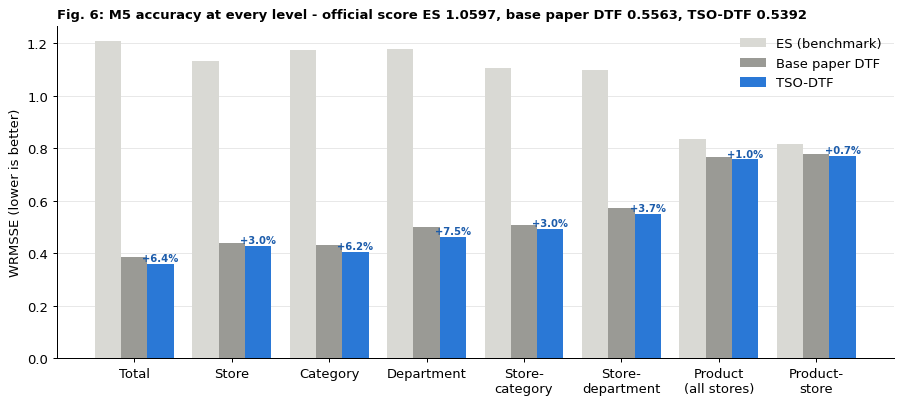

In [11]:
lv = list(LEVELS); vb = np.array([level_wrmsse(B, l) for l in lv]); ve = np.array([level_wrmsse(E, l) for l in lv]); ves = np.array([level_wrmsse(BM["ES"], l) for l in lv])
x = np.arange(len(lv)); fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x - .27, ves, .27, color="#d9d9d4", label="ES (benchmark)"); ax.bar(x, vb, .27, color=BASE, label="Base paper DTF"); ax.bar(x + .27, ve, .27, color=OURS, label="TSO-DTF")
for i in range(len(lv)): ax.text(x[i] + .27, ve[i] + .01, f"+{100 * (vb[i] - ve[i]) / vb[i]:.1f}%", ha="center", fontsize=8, color="#1c5cab", fontweight="bold")
ax.set_xticks(x, [l.replace(" (", "\n(").replace("-", "-\n") for l in lv]); ax.set_ylabel("WRMSSE (lower is better)"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_title(f"Fig. 6: M5 accuracy at every level - official score ES {official(BM['ES']):.4f}, base paper DTF {official(B):.4f}, TSO-DTF {official(E):.4f}", loc="left", fontweight="bold", fontsize=10.5)
save(fig, "fig06_m5_levels")


### Fig. 7 - Inventory performance (base paper Table 5 as a graph)
Daily order-up-to policy, 95% target, safety stock = z x past forecast RMSE, 14-day warm-up, lost sales.

                Mean inventory  ...  Bullwhip inventory
Naive                   4.2173  ...              2.5984
sNaive                  3.9250  ...              2.8740
MA                      2.7305  ...              1.1881
ES                      2.7108  ...              1.0388
CRO                     2.7816  ...              1.0157
ADIDA                   2.6646  ...              0.9626
Base paper DTF          2.6590  ...              1.0191
TSO-DTF                 2.6401  ...              0.9967

[8 rows x 5 columns]


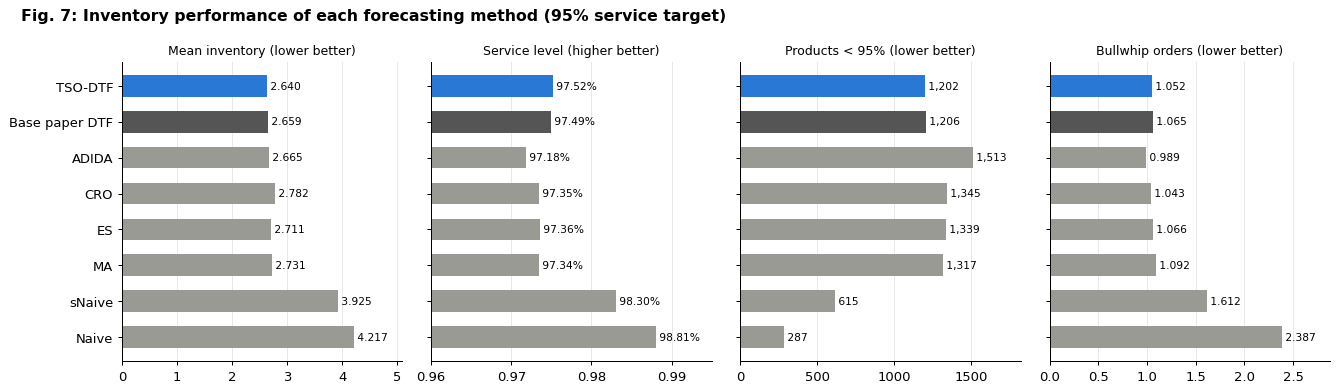

In [12]:
WARM = 14
def inventory(P, z=norm.ppf(0.95)):
    err = A - P; inv = np.zeros(N); O, I = [], []; so = np.zeros(N); avg_inv = np.zeros(N)
    for t in range(WARM, T):
        sig = np.sqrt(np.mean(err[:, :t] ** 2, axis=1)); o = np.maximum(0, np.ceil(np.maximum(P[:, t], 0) + z * sig - inv))
        av = inv + o; d = A[:, t]; so += d > av; inv = av - np.minimum(av, d); O.append(o); I.append(inv.copy())
    O, I = np.array(O).T, np.array(I).T; vd = A[:, WARM:].var(axis=1); okv = vd > 0; sl = 1 - so / (T - WARM)
    return {"Mean inventory": I.mean(), "Service level": sl.mean(), "Products < 95%": int((sl < .95).sum()),
            "Bullwhip orders": np.mean(O.var(axis=1)[okv] / vd[okv]), "Bullwhip inventory": np.mean(I.var(axis=1)[okv] / vd[okv])}
INV = pd.DataFrame({k: inventory(v) for k, v in ALL.items()}).T; print(INV.round(4))
fig, axs = plt.subplots(1, 4, figsize=(15, 4.4))
for ax, c_, fmt in zip(axs, ["Mean inventory", "Service level", "Products < 95%", "Bullwhip orders"], ["{:.3f}", "{:.2%}", "{:,.0f}", "{:.3f}"]):
    s_ = INV[c_]; ax.barh(s_.index, s_.values, color=[OURS if k == "TSO-DTF" else ("#555" if k == "Base paper DTF" else BASE) for k in s_.index], height=.6)
    for i, v_ in enumerate(s_.values): ax.text(v_, i, " " + fmt.format(v_), va="center", fontsize=8.5)
    if c_ == "Service level": ax.set_xlim(.96, .995)
    ax.set_xlim(right=ax.get_xlim()[1] * 1.15) if c_ != "Service level" else None
    ax.set_title(c_ + (" (higher better)" if c_ == "Service level" else " (lower better)"), fontsize=10); ax.grid(axis="y", visible=False)
    if ax is not axs[0]: ax.set_yticklabels([])
fig.suptitle("Fig. 7: Inventory performance of each forecasting method (95% service target)", x=.02, ha="left", fontweight="bold"); fig.tight_layout()
save(fig, "fig07_inventory")


### Fig. 8 - Accuracy per demand pattern (base paper Table C.8 as a graph)

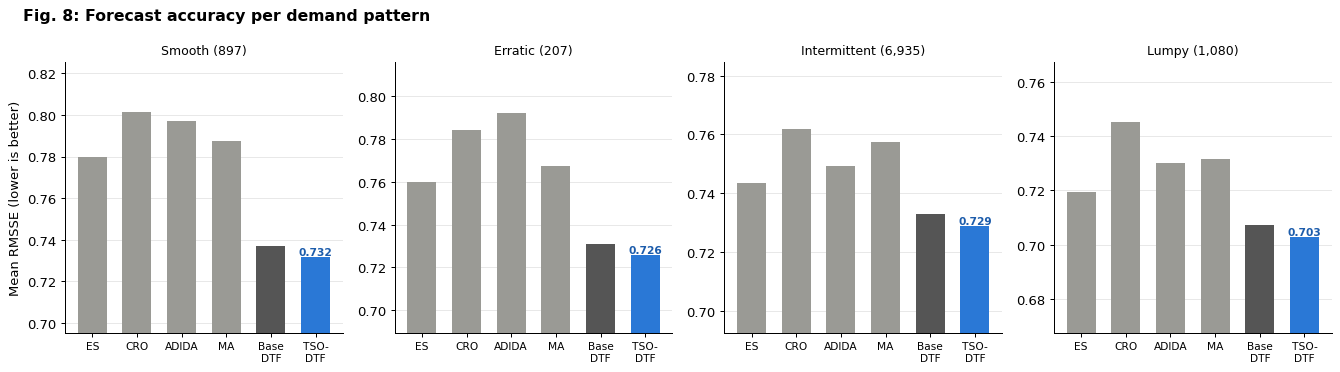

In [13]:
pats = ["smooth", "erratic", "intermittent", "lumpy"]; meths = ["ES", "CRO", "ADIDA", "MA", "Base paper DTF", "TSO-DTF"]
fig, axs = plt.subplots(1, 4, figsize=(15, 4.2), sharey=False)
for ax, p_ in zip(axs, pats):
    m_ = CLS == p_; v_ = [RS[k][0][m_].mean() for k in meths]
    ax.bar(range(len(meths)), v_, color=[OURS if k == "TSO-DTF" else ("#555" if k == "Base paper DTF" else BASE) for k in meths], width=.65)
    ax.set_ylim(min(v_) * .95, max(v_) * 1.03); ax.set_xticks(range(len(meths)), [k.replace("Base paper DTF", "Base\nDTF").replace("TSO-DTF", "TSO-\nDTF") for k in meths], fontsize=8.5)
    ax.text(5, v_[5], f"{v_[5]:.3f}", ha="center", va="bottom", fontsize=8.5, color="#1c5cab", fontweight="bold")
    ax.set_title(f"{p_.capitalize()} ({m_.sum():,})", fontsize=10); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("Mean RMSSE (lower is better)")
fig.suptitle("Fig. 8: Forecast accuracy per demand pattern", x=.02, ha="left", fontweight="bold"); fig.tight_layout()
save(fig, "fig08_by_demand_pattern")


# Part B - New graphs (not in the base paper)
### Fig. 9 - Ablation: what each optimization step adds

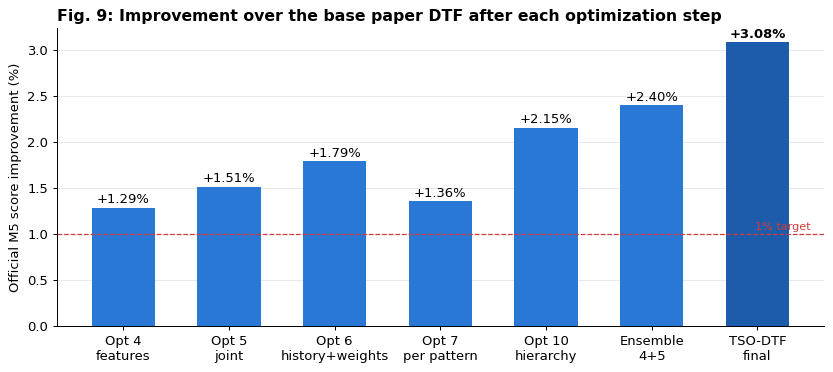

In [14]:
steps = ["Opt 4", "Opt 5", "Opt 6", "Opt 7", "Opt 10", "Ensemble 4+5", "TSO-DTF (final)"]; ob = official(B)
va = [100 * (ob - official(F[k])) / ob for k in steps]
fig, ax = plt.subplots(figsize=(11, 4.3)); ax.bar(range(len(steps)), va, color=[OURS] * (len(steps) - 1) + ["#1c5cab"], width=.6)
for i, v_ in enumerate(va): ax.text(i, v_ + .05, f"+{v_:.2f}%", ha="center", fontweight="bold" if i == len(steps) - 1 else "normal")
ax.axhline(1, color=NEG, ls="--", lw=1); ax.text(len(steps) - .5, 1.05, "1% target", color=NEG, ha="right", fontsize=9)
ax.set_xticks(range(len(steps)), ["Opt 4\nfeatures", "Opt 5\njoint", "Opt 6\nhistory+weights", "Opt 7\nper pattern", "Opt 10\nhierarchy", "Ensemble\n4+5", "TSO-DTF\nfinal"])
ax.set_ylabel("Official M5 score improvement (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Fig. 9: Improvement over the base paper DTF after each optimization step", loc="left", fontweight="bold")
save(fig, "fig09_ablation")


### Fig. 10 - How sure is the improvement? (7-day block bootstrap, 1,000 resamples)

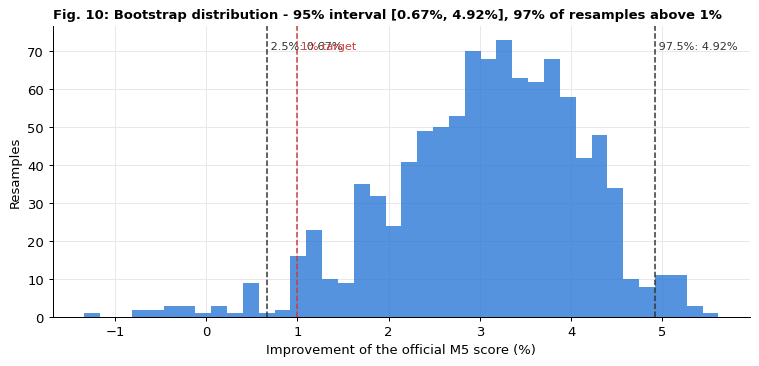

In [15]:
rng = np.random.default_rng(0); blocks = [np.arange(i, min(i + 7, T)) for i in range(0, T, 7)]; boot = []
for _ in range(1000):
    d_ = np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]); boot.append(100 * (official(B, d_) - official(E, d_)) / official(B, d_))
boot = np.array(boot); lo, hi = np.percentile(boot, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(10, 4.2)); ax.hist(boot, bins=40, color=OURS, alpha=.8)
for v_, l_, c_ in [(lo, f"2.5%: {lo:.2f}%", "#333"), (hi, f"97.5%: {hi:.2f}%", "#333"), (1, "1% target", NEG)]:
    ax.axvline(v_, color=c_, ls="--", lw=1.2); ax.text(v_, ax.get_ylim()[1] * .92, " " + l_, color=c_, fontsize=9)
ax.set_xlabel("Improvement of the official M5 score (%)"); ax.set_ylabel("Resamples")
ax.set_title(f"Fig. 10: Bootstrap distribution - 95% interval [{lo:.2f}%, {hi:.2f}%], {100 * np.mean(boot > 1):.0f}% of resamples above 1%", loc="left", fontweight="bold", fontsize=10.5)
save(fig, "fig10_bootstrap")


### Fig. 11 - Per-product improvement

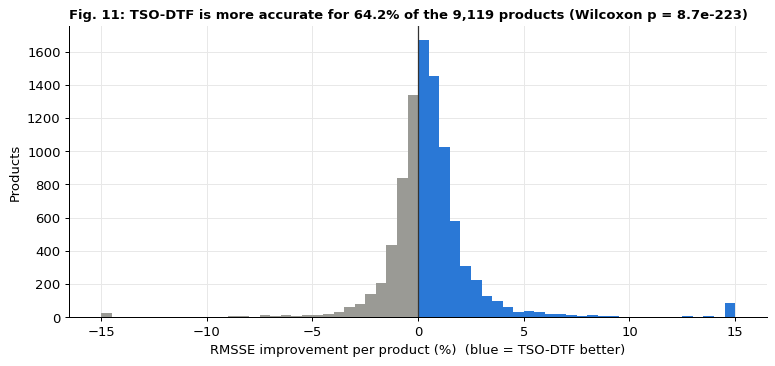

In [16]:
rb, re_ = RS["Base paper DTF"][0], RS["TSO-DTF"][0]; diff = 100 * (rb - re_) / rb
fig, ax = plt.subplots(figsize=(10, 4.2)); bins = np.linspace(-15, 15, 61)
ax.hist(np.clip(diff, -15, 15), bins=bins, color=BASE); ax.hist(np.clip(diff[diff > 0], -15, 15), bins=bins, color=OURS)
ax.axvline(0, color="#333", lw=1); ax.set_xlabel("RMSSE improvement per product (%)  (blue = TSO-DTF better)"); ax.set_ylabel("Products")
ax.set_title(f"Fig. 11: TSO-DTF is more accurate for {100 * np.mean(re_ < rb):.1f}% of the {N:,} products (Wilcoxon p = {wilcoxon(re_, rb).pvalue:.1e})", loc="left", fontweight="bold", fontsize=10.5)
save(fig, "fig11_per_product")


### Fig. 12 - Service level vs stock (decision support)

All figures saved in /content/drive/MyDrive/m5_results/base_paper_figures


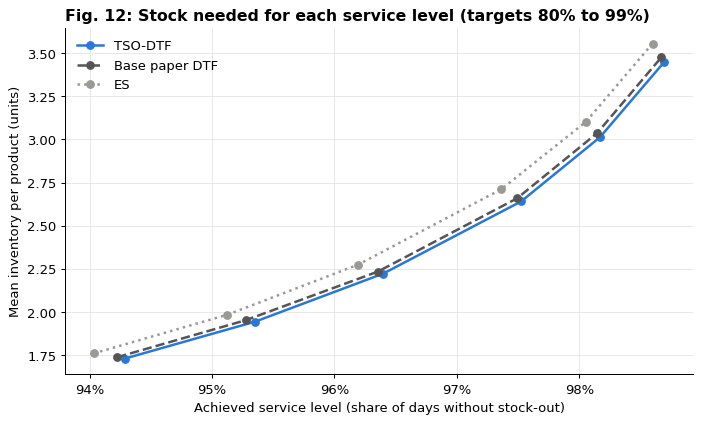

In [17]:
targets = [0.80, 0.85, 0.90, 0.95, 0.975, 0.99]
fig, ax = plt.subplots(figsize=(9, 5))
for k, c_, ls_ in [("TSO-DTF", OURS, "-"), ("Base paper DTF", "#555", "--"), ("ES", BASE, ":")]:
    pts = [inventory(ALL[k], norm.ppf(s_)) for s_ in targets]
    ax.plot([p["Service level"] for p in pts], [p["Mean inventory"] for p in pts], ls_, marker="o", color=c_, lw=2, label=k)
ax.set_xlabel("Achieved service level (share of days without stock-out)"); ax.set_ylabel("Mean inventory per product (units)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v_, _: f"{v_:.0%}")); ax.legend(frameon=False)
ax.set_title("Fig. 12: Stock needed for each service level (targets 80% to 99%)", loc="left", fontweight="bold")
save(fig, "fig12_service_vs_stock")
print("All figures saved in", FIG_DIR)
